In [30]:
# 1. Series de Tiempo... Identificacion
# Diego Andres Gonzalez Torrealba
# Serie asignada: EURO
# Tipo de cambio entre Euro a Pesos chilenos (EUR/CLP)
# La serie representa el valor del euro expresado en pesos a lo largo del tiempo.


In [31]:
# 2. Bibliotecas
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
# 3. Cargas de archivo
df_raw = pd.read_excel('EURO.xlsx')

In [33]:
# 4. Exploracion inicial de los datos
# Primeras cinco observaciones
print("Primeras 5 observaciones")
display(df_raw.head())

# Nombre de las columnas
print("\n Columnas")
print(df_raw.columns.tolist())

# Cantidad de filas y columnas
print("\n Cantidades (Filas, Columnas)")
print(df_raw.shape)

# Tipos de datos
print("\n Tipos de datos")
print(df_raw.dtypes)

# Existencia de valores faltantes
print("\n Valores faltantes")
print(df_raw.isnull().sum())

Primeras 5 observaciones


,"Fecha,Valor"
0,"2020-01-02,839.58"
1,"2020-01-03,842.45"
2,"2020-01-04,"
3,"2020-01-05,"
4,"2020-01-06,847.38"



 Columnas
['Fecha,Valor']

 Cantidades (Filas, Columnas)
(2424, 1)

 Tipos de datos
Fecha,Valor    object
dtype: object

 Valores faltantes
Fecha,Valor    0
dtype: int64


In [34]:
#Nota personal: me doy cuenta de que segun el codigo hay 0 datos faltantes.. pero no tiene sentido porque cuando veo excel los dias sabado y domingo no tienen dato de euro.
#Habra que solucionarlo.


In [35]:
# 5. Preparacion de la serie.
# Voy a separar la columan en 2.. para poder diferenciar las fechas de el valor del euro.
# Luego le dare el formato correcto a cada columna y vere como quedo la base.
df = df_raw['Fecha,Valor'].str.split(',', expand=True)
df.columns = ['Fecha', 'Valor']

df['Fecha'] = pd.to_datetime(df['Fecha'])

df['Valor'] = pd.to_numeric(df['Valor'])

df = df.sort_values(by='Fecha').reset_index(drop=True)

#Lo ultimo que hice fue re ordenar la base por fecha para asegurar que no existan errores.
print(df.head())


       Fecha   Valor
0 2020-01-02  839.58
1 2020-01-03  842.45
2 2020-01-04     NaN
3 2020-01-05     NaN
4 2020-01-06  847.38


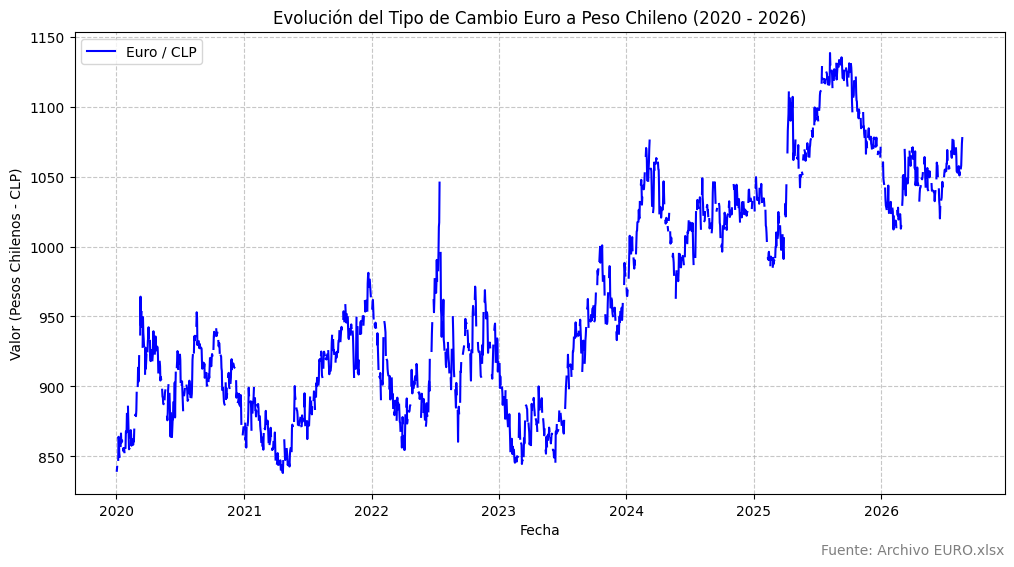

In [36]:
# 6. Grafico
plt.figure(figsize=(12, 6))
plt.plot(df['Fecha'], df['Valor'], label='Euro / CLP', color='blue', linestyle='-', linewidth=1.5)
plt.title('Evolución del Tipo de Cambio Euro a Peso Chileno (2020 - 2026)')
plt.xlabel('Fecha')
plt.ylabel('Valor (Pesos Chilenos - CLP)')
plt.figtext(0.9, 0.01, 'Fuente: Archivo EURO.xlsx', ha='right', fontsize=10, color='gray')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

La gráfica evidencia una clara tendencia al alza, mostrando una apreciación progresiva del euro frente al peso con el paso del tiempo, sin embargo, esta evolución está fuertemente marcada por una alta volatilidad.

Existen aumentos puntuales muy importantes, destacando especialmente el peak ocurrido a mediados del año 2022. Por el contrario, también se registran un par de disminuciones significativas, como las caídas observadas a inicios de los años 2021 y 2023.

En el último periodo analizado, es decir, desde 2024 en adelante, se aprecian valores especialmente altos en comparación a los primeros años de la serie. El principal patrón que se puede extraer de esta volátil serie de tiempo es que, después de enfrentar fuertes correcciones a la baja, el euro tiende a recuperarse alcanzando niveles cada vez mayores.